# ЛР3 - manifold learning: MDS, LLE, Isomap

## Окружение

In [1]:
%pip install -q plotly scikit-learn scipy seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import inspect
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.manifold import MDS

pd.set_option('display.width', 160)

# В sklearn >= 1.8 параметры MDS переименованы (dissimilarity -> metric, metric -> metric_mds).
# Вспомогательная функция создаёт MDS одинаково в любой версии.
_MDS_PARAMS = inspect.signature(MDS).parameters

def make_mds(n_components=2, precomputed=False, metric=True, **kwargs):
    if 'metric_mds' in _MDS_PARAMS:            # sklearn >= 1.8
        kwargs['metric_mds'] = metric
        if precomputed:
            kwargs['metric'] = 'precomputed'
    else:                                       # sklearn <= 1.7
        kwargs['metric'] = metric
        if precomputed:
            kwargs['dissimilarity'] = 'precomputed'
    return MDS(n_components=n_components, **kwargs)

#Connections Visualization

Данные: надпись HELLO, изогнутая в S. Слева связи LLE (только соседи), справа MDS (все пары).

In [3]:
#@title Pairwise distances
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
import numpy as np

def make_hello(N=1000, rseed=42):
  # Make a plot with "HELLO" text; save as PNG
  fig, ax = plt.subplots(figsize=(4, 1))
  fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
  ax.axis('off')
  ax.text(0.5, 0.4, 'HELLO', va='center', ha='center', weight='bold', size=85)
  fig.savefig('hello.png')
  plt.close(fig)
  # Open this PNG and draw random points from it
  from matplotlib.image import imread
  data = imread('hello.png')[::-1, :, 0].T
  rng = np.random.RandomState(rseed)
  X = rng.rand(4 * N, 2)
  i, j = (X * data.shape).astype(int).T
  mask = (data[i, j] < 1)
  X = X[mask]
  X[:, 0] *= (data.shape[0] / data.shape[1])
  X = X[:N]
  return X[np.argsort(X[:, 0])]

X = make_hello(1000)
colorize = dict(c=X[:, 0], cmap=plt.get_cmap('rainbow', 5))

import numpy as np

# arrange "hello" in non-linear, S-shaped way
def make_hello_s_curve(X):
  t = (X[:, 0] - 2) * 0.75 * np.pi
  x = np.sin(t)
  y = X[:, 1]
  z = np.sign(t) * (np.cos(t) - 1)
  return np.vstack((x, y, z)).T
XS = make_hello_s_curve(X)

from plotly.subplots import make_subplots
import plotly.graph_objects as go
colors = ['rgb(' + np.array2string(c[:-1], formatter={'float_kind':lambda x:  "%.0f" % (x * 255)}, separator=',')[1:-1] + ')' for c in colorize['cmap'](0.255*colorize['c'])]

fig = make_subplots(rows=1, cols=2, specs=[[{"type": "scene"}, {"type": "scene"}]])

fig.add_trace(go.Scatter3d(x=XS[:, 0], y=XS[:, 1], z=XS[:, 2],
                           mode='markers', name='datapoints (LEFT)',
                           marker=dict(
                              size=5,
                              opacity=0.8,
                              color=colors
                            )
                           ), row=1, col=1)
fig.add_trace(go.Scatter3d(x=XS[:, 0], y=XS[:, 1], z=XS[:, 2],
                           mode='markers', name='datapoints (RIGHT)',
                           marker=dict(
                              size=5,
                              opacity=0.8,
                              color=colors
                            )
                           ), row=1, col=2)

# construct lines for LLE
from sklearn.neighbors import NearestNeighbors

N_neighbours = 100

rng = np.random.RandomState(42)
ind = rng.permutation(len(X))
nbrs = NearestNeighbors(n_neighbors=N_neighbours, radius=100.0).fit(XS).kneighbors(XS[ind[:100]])[1]
lines_LLE = []
for i in range(100):
  for j in nbrs[i]:
    lines_LLE = lines_LLE + [XS[ind[i]], XS[j], np.array([None, None, None])]
lines_LLE = np.array(lines_LLE)

fig.add_trace(go.Scatter3d(
    x=lines_LLE[:, 0],
    y=lines_LLE[:, 1],
    z=lines_LLE[:, 2],
    mode='lines', opacity=0.2,
    line={'color': 'rgb(0,0,0)', 'width': 1},
    name='LLE connections'
), row=1, col=1)

# construct lines for MDS
lines_MDS = []
for i in ind[:100]:
  for j in ind[100:200]:
    lines_MDS = lines_MDS + [XS[i], XS[j], np.array([None, None, None])]
lines_MDS = np.array(lines_MDS)

fig.add_trace(go.Scatter3d(
    x=lines_MDS[:, 0],
    y=lines_MDS[:, 1],
    z=lines_MDS[:, 2],
    mode='lines', opacity=0.1,
    line={'color': 'rgb(0,0,0)', 'width': 1},
    name='MDS connections'
), row=1, col=2)

fig.show()


LLE связывает точки вдоль поверхности, MDS - напрямую сквозь изгиб, поэтому MDS её не развернёт.

#Sklearn manifold learning methods

Используйте следующий пример, чтобы получить представление о том, как работает многообразное обучение. 
* Попробуйте разные параметры для MDS и Isomap. Обратите внимание, что `n_neighbours` **значительно** меняет результат. Попробуйте разные значения, чтобы увидеть эффект 
* Реализуйте свою собственную поверхность, изменив функцию custom(X)`. В качестве примера приведена рулетка.

- Своя поверхность `custom` - сферический пояс: кривизна > 0, поэтому развернуть без искажений нельзя.
- `wave` - гофрированный лист.

In [4]:
from sklearn.manifold import LocallyLinearEmbedding
from sklearn.metrics import pairwise_distances

def linear_embedding(datapoints):
  model = LocallyLinearEmbedding(n_neighbors=100, n_components=2, method='modified', eigen_solver='dense')
  return model.fit_transform(datapoints)

def multidim_scaling(datapoints):
  model = make_mds(n_components=2, precomputed=True, random_state=1, n_init=1)
  D = pairwise_distances(datapoints)
  return model.fit_transform(D)

from sklearn.manifold import Isomap
def isomap(datapoints):
  model = Isomap(n_components = 2, n_neighbors=200)
  return model.fit_transform(datapoints)


def _normalize(t):
  return (t - t.min()) / (t.max() - t.min())

def custom(X):
  """Собственная поверхность: «сферический пояс» (участок единичной сферы, K > 0)."""
  lon = (_normalize(X[:, 0]) - 0.5) * 1.6 * np.pi     # долгота
  lat = (_normalize(X[:, 1]) - 0.5) * 0.5 * np.pi     # широта
  return np.vstack([np.cos(lat) * np.cos(lon),
                    np.cos(lat) * np.sin(lon),
                    np.sin(lat)]).T

def wave(X):
  """Дополнительная поверхность: «гофрированный лист» z = 0.3 sin(4u) (K = 0)."""
  u = X[:, 0] - X[:, 0].min()
  v = X[:, 1] - X[:, 1].min()
  return np.vstack([u, v, 0.3 * np.sin(4 * u)]).T

Виджет работает только в Colab.

In [5]:
#@title Explore manifold learning
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib import cm
import seaborn as sns

def make_hello(N=1000, rseed=42):
  import seaborn as sns; sns.set();
  # Make a plot with "HELLO" text; save as PNG
  fig, ax = plt.subplots(figsize=(4, 1))
  fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
  ax.axis('off')
  ax.text(0.5, 0.4, 'HELLO', va='center', ha='center', weight='bold', size=85)
  fig.savefig('hello.png')
  plt.close(fig)
  # Open this PNG and draw random points from it
  from matplotlib.image import imread
  data = imread('hello.png')[::-1, :, 0].T
  rng = np.random.RandomState(rseed)
  X = rng.rand(4 * N, 2)
  i, j = (X * data.shape).astype(int).T
  mask = (data[i, j] < 1)
  X = X[mask]
  X[:, 0] *= (data.shape[0] / data.shape[1])
  X = X[:N]
  return X[np.argsort(X[:, 0])]

X = make_hello(1000)
colorize = dict(c=X[:, 0], cmap=plt.get_cmap('rainbow', 5))
colors = ['rgb(' + np.array2string(c[:-1], formatter={'float_kind':lambda x:  "%.0f" % (x * 255)}, separator=',')[1:-1] + ')' for c in colorize['cmap'](0.255*colorize['c'])]


def unwind_manifold(datapoints, method):
  methods = {'lle': linear_embedding, 'mds': multidim_scaling, 'isomap': isomap}
  return methods[method](datapoints)

def roll(X):
  b_x = np.min(X[:,0])
  k_x = (np.max(X[:,0]) - np.min(X[:,0])) / (2 * np.pi - 0.2)
  b_y = b_x - 0.2
  k_y = 0.5 * (np.max(X[:,1]) - np.min(X[:,1]))
  params = [[(x[0] - b_x)/k_x, (x[1] - b_y)/k_y] for x in X]
  roulette = np.array([[(2 + p[0]) * np.cos(2 * p[0]), (2 + p[0]) * np.sin(2 * p[0]), 2.0 * p[1]] for p in params])
  return roulette

def s_curve(X):
  t = (X[:, 0] - 2) * 0.75 * np.pi
  x = np.sin(t)
  y = X[:, 1]
  z = np.sign(t) * (np.cos(t) - 1)
  return np.vstack((x, y, z)).T

def plane(X):
  p = np.array([[x[0], x[1], x[0] + x[1]] for x in X])
  return p

def mobius(X):
  b_x = np.min(X[:,0])
  k_x = (np.max(X[:,0]) - np.min(X[:,0])) / (2 * np.pi - 0.1)
  b_y = 0.5 * (np.max(X[:,1]) + np.min(X[:,1]))
  k_y = 0.5 * (np.max(X[:,1]) - np.min(X[:,1]))
  params = [[(x[0] - b_x)/k_x, (x[1] - b_y)/k_y] for x in X]
  mobius = np.array([[(1.0 + p[1]/2.0 * np.cos(p[0]/2)) * np.cos(p[0]), (1.0 + p[1]/2.0 * np.cos(p[0]/2)) * np.sin(p[0]), p[1]/2.0 * np.sin(p[0]/2)] for p in params])
  return mobius

def cylinder(X):
  b_x = np.min(X[:,0])
  k_x = (np.max(X[:,0]) - np.min(X[:,0])) / (2 * np.pi - 0.1)
  b_y = 0.5 * (np.max(X[:,1]) + np.min(X[:,1]))
  k_y = 0.5 * (np.max(X[:,1]) - np.min(X[:,1]))
  params = [[(x[0] - b_x)/k_x, (x[1] - b_y)/k_y] for x in X]
  cylinder = np.array([[2.0 * np.cos(p[0]), 2.0 * np.sin(p[0]), p[1]] for p in params])
  return cylinder

def helicoid(X):
  b_x = np.min(X[:,0])
  k_x = (np.max(X[:,0]) - np.min(X[:,0])) / (2 * np.pi)
  b_y = 0.5 * (np.max(X[:,1]) + np.min(X[:,1]))
  k_y = 0.5 * (np.max(X[:,1]) - np.min(X[:,1]))
  params = [[(x[0] - b_x)/k_x, (x[1] - b_y)/k_y] for x in X]
  helicoid = np.array([[p[1] * np.cos(p[0]), p[1] * np.sin(p[0]), 2.0 * p[0]] for p in params])
  return helicoid

def cone(X):
  b_x = np.min(X[:,0])
  k_x = (np.max(X[:,0]) - np.min(X[:,0])) / (2 * np.pi - 0.2)
  b_y = b_x - 0.2
  k_y = 0.5 * (np.max(X[:,1]) - np.min(X[:,1]))
  params = [[(x[0] - b_x)/k_x, (x[1] - b_y)/k_y] for x in X]
  cone = np.array([[p[1] * np.cos(p[0]), p[1] * np.sin(p[0]), 2.0 * p[1]] for p in params])
  return cone

def transform_to_3d(x, manifold):
  funcs = {'s_curve': s_curve, 'mobius': mobius, 'cylinder': cylinder,
           'helicoid': helicoid, 'cone': cone, 'custom': custom, 'plane': plane,
           'roll': roll}
  return funcs[manifold](x)

def plot_unwinded(x):
  fig = plt.figure(figsize=(10,10))
  ax = fig.gca()
  ax.tick_params(axis="y",direction="in", pad=-40)
  ax.tick_params(axis="x",direction="in", pad=-15)
  ax.scatter(x[:, 0], x[:, 1], **colorize)
  #ax.set_ylim(0.15, -0.15);
  plt.close(fig)
  return fig


import base64
import io

def figure_to_base64(fig):
  buf = io.BytesIO()
  fig.savefig(buf, format='png', bbox_inches='tight', pad_inches=0);
  image_base64 = base64.b64encode(buf.getvalue()).decode('utf-8').replace('\n', '')
  buf.close()
  return image_base64

import json
from IPython.display import display, clear_output
from scipy.spatial import Delaunay

def invoke(manifold, method):
  man = transform_to_3d(X, manifold)
  unw = unwind_manifold(man, method)
  figr = plot_unwinded(unw)
  image_base64 = figure_to_base64(figr)

  x_ = np.linspace(np.min(X[:, 0]), np.max(X[:, 0]), num=100)
  y_ = np.linspace(np.min(X[:, 1]), np.max(X[:, 1]), num=100)
  xx, yy = np.meshgrid(x_, y_)
  x_vec = np.transpose(np.vstack([xx.ravel(), yy.ravel()]))
  Y = transform_to_3d(x_vec, manifold) #[:,2].reshape((x_.shape[0],y_.shape[0]))

  tri = Delaunay(x_vec, )
  simplices = tri.simplices
  I, J, K = ([triplet[c] for triplet in tri.simplices] for c in range(3))
  #print(Y[:,0].shape, Y[:,1].shape, Y[:,2].shape)
  return IPython.display.JSON({'image': image_base64,
                               'g_x': Y[:,0].tolist(), 'g_y': Y[:,1].tolist(), 'g_z': Y[:,2].tolist(),
                               's_x': man[:, 0].tolist(), 's_y': man[:, 1].tolist(), 's_z': man[:, 2].tolist(), 's_c': colors,
                               'simplices': [I, J, K]})


import IPython


main_str = '''
  <script src="https://cdn.plot.ly/plotly-latest.min.js"></script>
  <script type="application/javascript">

    var params = null;
    var debug_txt = "";
    var bg_image = new Image();


    function draw() {
      var canvas = document.getElementById('canvas');
      if (canvas.getContext) {
        var ctx = canvas.getContext('2d');

        ctx.clearRect(0, 0, canvas.width, canvas.height); // cleanup before start
        ctx.drawImage(bg_image, 0, 0, 600, 600);
        ctx.strokeRect(0, 0, 600, 600); // field

        ctx.font = '20px serif';
        ctx.fillStyle = 'black';
        ctx.fillText(debug_txt, 200, 200);
      }
    }

    var timer

   function plot_3d(g_x, g_y, g_z, simp)
   {
     cell_for_plot = document.getElementById('for_plotly_plot');
     //Plotly.deleteTraces(cell_for_plot, [0, 1]);
     var data = [{
           x: g_x,
           y: g_y,
           z: g_z,
           i: simp[0],
           j: simp[1],
           k: simp[2],
           type: 'mesh3d',
           opacity: 0.4,
           showscale: false,
           colorscale: "Viridis"
        }];
     var layout = {
          title: 'Manifold',
          autosize: false,
          width: 600,
          height: 600,
          showlegend: false,
          scene: {
            camera: {
              up: {x: 0, y: 1, z: 0},
              center: {x: 0, y: 0, z: 0},
              eye: {x: 0.0, y: -1.0, z: 1.4}
            }
          }
        };
     //debug_txt = 'before plot';
     Plotly.newPlot(cell_for_plot, data, layout);
     //debug_txt = 'go';
   }

   function plot_scatter(s_x, s_y, s_z, colors)
   {
     cell_for_plot = document.getElementById('for_plotly_plot');
     var data = [{
           x: s_x,
           y: s_y,
           z: s_z,
           type: 'scatter3d',
           mode: 'markers',
           marker: {
             size: 4,
             color: colors,
             line: {
               width: 2,
               color: 'rgba(0, 0, 0, 0.5)'
             }
           }
        }];
     var layout = {
          title: 'Manifold',
          autosize: false,
          width: 600,
          height: 600,
          showlegend: false,
          scene: {
            camera: {
              up: {x: 0, y: 1, z: 0},
              center: {x: 0, y: 0, z: 0},
              eye: {x: 0.0, y: -1.0, z: 1.4}
            }
          }
        };
    //Plotly.newPlot(cell_for_plot, data, layout);
    Plotly.plot(cell_for_plot, data, {});
   }


    var cur_depth = 100;

    async function calculate() {
      var e = document.getElementById("select_kernel");
      var ker_name = e.options[e.selectedIndex].value;
      var e1 = document.getElementById("select_metric");
      var metric_name = e1.options[e1.selectedIndex].value;
      const result = await google.colab.kernel.invokeFunction('notebook.InvSVM', [ker_name, metric_name], {});
      params = result.data['application/json'];

      bg_image.src = 'data:image/  png;base64,' + params.image;
      //cell_for_plot = document.getElementById('for_plotly_plot');

      plot_3d(params.g_x, params.g_y, params.g_z, params.simplices);
      plot_scatter(params.s_x, params.s_y, params.s_z, params.s_c);

    }

 </script>

<div id="everything" style="height:600px;">
<div id="for_plotly_plot" style="position:absolute; top:0px; left:0px; height:600px; width:600px;">
</div>
<div id="custom_controls" style="position:absolute; top:0px; left:600px;">
  <canvas id="canvas" width="800" height="600"></canvas>
  <div style="position:absolute; top:200px; left:625px;">
   Manifold:<br>
   <select id="select_kernel">
       <option value="plane">Plane in 3D</option>
       <option value="mobius">Mobius strip</option>
       <option value="s_curve">S-shaped sheet</option>
       <option value="cylinder">Cylinder</option>
       <option value="helicoid">Helicoid</option>
       <option value="cone">Cone</option>
       <option value="roll">Swiss Roll</option>
       <option value="custom">Custom Surface</option>
   </select>
   <br>
   Method:
   <br>
   <select id="select_metric">
       <option value="lle">Locally Linear Embedding (LLE)</option>
       <option value="mds">Multidimensional Scaling (MDS)</option>
       <option value="isomap">Isomap (Iso)</option>
   </select>
   <br><br>
    <button type="button" onclick="calculate();">
      Unfold
    </button>
  </div>
</div>
<div>

<script>
function init()
{
  timer = setInterval(draw, 10);
}

init();
</script>
'''

# виджет работает только в Colab
try:
    from google.colab import output
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    display(IPython.display.HTML(main_str))
    output.register_callback('notebook.InvSVM', invoke)
else:
    print("Интерактивный виджет работает только в Google Colab — ниже приведено статическое сравнение.")

Интерактивный виджет работает только в Google Colab — ниже приведено статическое сравнение.


## Все поверхности × все методы
Метрики относительно исходной надписи: Procrustes disparity (меньше - лучше) и trustworthiness (больше - лучше).

In [6]:
from scipy.spatial import procrustes
from sklearn.manifold import trustworthiness

SURFACES = {'plane': plane, 's_curve': s_curve, 'roll': roll, 'cylinder': cylinder,
            'cone': cone, 'helicoid': helicoid, 'mobius': mobius, 'wave': wave,
            'custom (сфера)': custom}
METHODS = {'LLE': linear_embedding, 'MDS': multidim_scaling, 'Isomap': isomap}

def unfold_quality(X2d, emb, k=10):
    _, _, disparity = procrustes(X2d, emb)
    return disparity, trustworthiness(X2d, emb, n_neighbors=k)

results, embeddings = [], {}
for s_name, s_func in SURFACES.items():
    X3 = s_func(X)
    for m_name, m_func in METHODS.items():
        t0 = time.time()
        emb = m_func(X3)
        dt = time.time() - t0
        disp, tw = unfold_quality(X, emb)
        embeddings[(s_name, m_name)] = emb
        results.append({'Поверхность': s_name, 'Метод': m_name,
                        'Procrustes': disp, 'Trustworthiness': tw, 'Время, с': dt})

res_df = pd.DataFrame(results)
print(res_df.pivot(index='Поверхность', columns='Метод', values='Procrustes').round(3).loc[list(SURFACES)])
print()
print(res_df.pivot(index='Поверхность', columns='Метод', values='Trustworthiness').round(3).loc[list(SURFACES)])

Метод           Isomap    LLE    MDS
Поверхность                         
plane            0.012  0.292  0.063
s_curve          0.196  0.300  0.286
roll             0.873  0.881  0.881
cylinder         0.704  0.578  0.701
cone             0.697  0.741  0.725
helicoid         0.015  0.420  0.038
mobius           0.729  0.743  0.722
wave             0.004  0.295  0.001
custom (сфера)   0.387  0.302  0.468

Метод           Isomap    LLE    MDS
Поверхность                         
plane            0.999  0.997  0.998
s_curve          0.962  0.996  0.947
roll             0.936  0.971  0.938
cylinder         0.947  0.893  0.959
cone             0.991  0.934  0.978
helicoid         0.998  0.996  0.995
mobius           0.997  0.998  0.998
wave             1.000  0.996  1.000
custom (сфера)   0.965  0.996  0.991


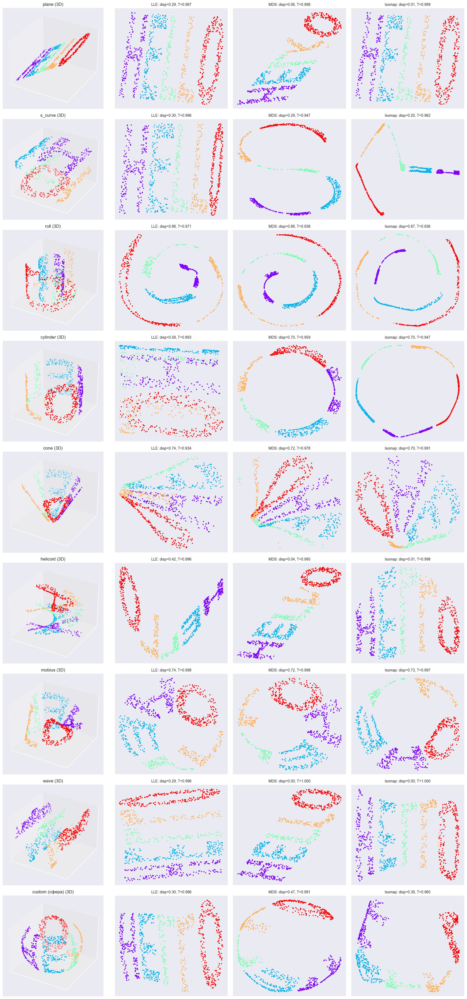

In [7]:
cols = colorize['cmap'](colorize['c'] / colorize['c'].max())
fig = plt.figure(figsize=(18, 4.2 * len(SURFACES)))
for i, (s_name, s_func) in enumerate(SURFACES.items()):
    X3 = s_func(X)
    ax = fig.add_subplot(len(SURFACES), 4, 4 * i + 1, projection='3d')
    ax.scatter(X3[:, 0], X3[:, 1], X3[:, 2], c=cols, s=4)
    ax.set_title(f'{s_name} (3D)')
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
    for j, m_name in enumerate(METHODS, start=2):
        emb = embeddings[(s_name, m_name)]
        r = res_df[(res_df['Поверхность'] == s_name) & (res_df['Метод'] == m_name)].iloc[0]
        ax = fig.add_subplot(len(SURFACES), 4, 4 * i + j)
        ax.scatter(emb[:, 0], emb[:, 1], c=cols, s=4)
        ax.set_title(f"{m_name}: disp={r['Procrustes']:.2f}, T={r['Trustworthiness']:.3f}", fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

LLE k = 100, Isomap k = 200.
- plane, wave, helicoid: Isomap почти идеален.
- S-кривую лучше всех развернул LLE.
- roll, cylinder, cone, mobius не развернул никто: короткие замыкания, замкнутость, вершина конуса, неориентируемость.
- Сфера читается, но с искажениями.

Оси подграфиков масштабированы по-разному, а LLE ещё и нормирует оси - для LLE смотрю на T.

## 2. Влияние `n_neighbors` на Isomap

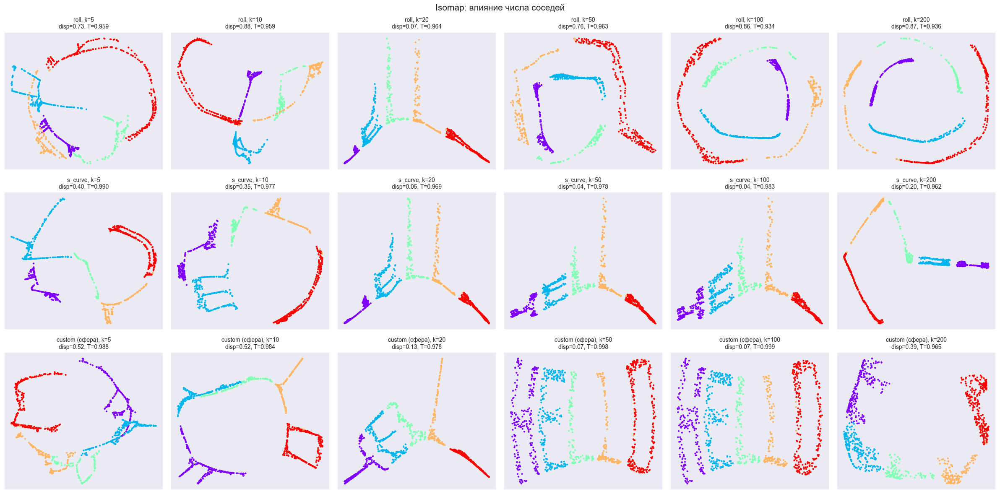

Поверхность  custom (сфера)   roll  s_curve
k                                          
5                     0.519  0.733    0.398
10                    0.521  0.878    0.354
20                    0.134  0.067    0.053
50                    0.071  0.759    0.044
100                   0.065  0.859    0.041
200                   0.387  0.873    0.196


In [8]:
def isomap_k(datapoints, k):
    return Isomap(n_components=2, n_neighbors=k).fit_transform(datapoints)

ks = [5, 10, 20, 50, 100, 200]
surf_list = ['roll', 's_curve', 'custom (сфера)']
fig, axes = plt.subplots(len(surf_list), len(ks), figsize=(4 * len(ks), 4 * len(surf_list)))
iso_rows = []
for i, s_name in enumerate(surf_list):
    X3 = SURFACES[s_name](X)
    for j, k in enumerate(ks):
        emb = isomap_k(X3, k)
        disp, tw = unfold_quality(X, emb)
        iso_rows.append({'Поверхность': s_name, 'k': k, 'Procrustes': disp, 'Trustworthiness': tw})
        axes[i, j].scatter(emb[:, 0], emb[:, 1], c=cols, s=4)
        axes[i, j].set_title(f'{s_name}, k={k}\ndisp={disp:.2f}, T={tw:.3f}', fontsize=10)
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
plt.suptitle('Isomap: влияние числа соседей', fontsize=15)
plt.tight_layout(); plt.show()

iso_df = pd.DataFrame(iso_rows)
print(iso_df.pivot(index='k', columns='Поверхность', values='Procrustes').round(3))

- roll разворачивается только при k = 20: при малом k граф несвязен (буквы отдельно), при большом - замыкания между витками.
- s_curve: k = 20–100; сфера: k = 50–100.
- Надпись выходит «веером»: область невыпуклая (пробелы между буквами).

## LLE: n_neighbors

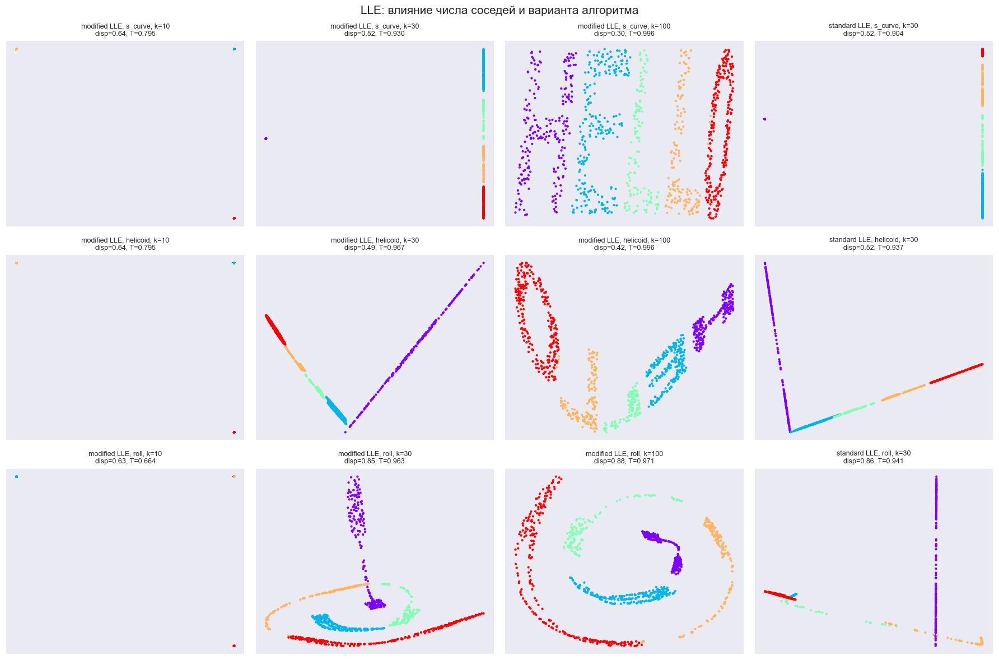

In [9]:
def lle_k(datapoints, k, method='modified'):
    return LocallyLinearEmbedding(n_neighbors=k, n_components=2, method=method,
                                  eigen_solver='dense', random_state=0).fit_transform(datapoints)

ks_lle = [10, 30, 100]
surf_lle = ['s_curve', 'helicoid', 'roll']
fig, axes = plt.subplots(len(surf_lle), len(ks_lle) + 1, figsize=(4.5 * (len(ks_lle) + 1), 4 * len(surf_lle)))
for i, s_name in enumerate(surf_lle):
    X3 = SURFACES[s_name](X)
    for j, k in enumerate(ks_lle):
        emb = lle_k(X3, k)
        disp, tw = unfold_quality(X, emb)
        axes[i, j].scatter(emb[:, 0], emb[:, 1], c=cols, s=4)
        axes[i, j].set_title(f'modified LLE, {s_name}, k={k}\ndisp={disp:.2f}, T={tw:.3f}', fontsize=9)
    emb = lle_k(X3, 30, method='standard')
    disp, tw = unfold_quality(X, emb)
    axes[i, -1].scatter(emb[:, 0], emb[:, 1], c=cols, s=4)
    axes[i, -1].set_title(f'standard LLE, {s_name}, k=30\ndisp={disp:.2f}, T={tw:.3f}', fontsize=9)
    for ax in axes[i]:
        ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('LLE: влияние числа соседей и варианта алгоритма', fontsize=15)
plt.tight_layout(); plt.show()

- k = 10 → всё схлопывается в 2–3 точки: граф несвязен, компоненты уходят в точки.
- k = 100 → S-кривая развёрнута идеально.
- Standard LLE вырождается в линии, modified - нет.

## MDS: варианты

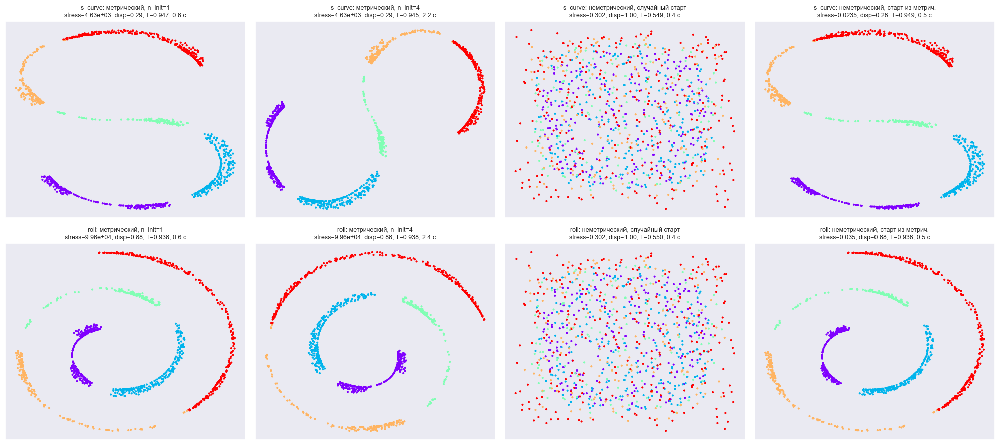

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for i, s_name in enumerate(['s_curve', 'roll']):
    X3 = SURFACES[s_name](X)
    D = pairwise_distances(X3)
    emb_metric = None
    variants = [('метрический, n_init=1', dict(metric=True, n_init=1), 'random'),
                ('метрический, n_init=4', dict(metric=True, n_init=4), 'random'),
                ('неметрический, случайный старт', dict(metric=False, n_init=1), 'random'),
                ('неметрический, старт из метрич.', dict(metric=False, n_init=1), 'metric')]
    for j, (title, kw, init) in enumerate(variants):
        t0 = time.time()
        model = make_mds(2, precomputed=True, random_state=1, max_iter=300, **kw)
        emb = model.fit_transform(D, init=emb_metric if init == 'metric' else None)
        if j == 0:
            emb_metric = emb
        disp, tw = unfold_quality(X, emb)
        axes[i, j].scatter(emb[:, 0], emb[:, 1], c=cols, s=4)
        axes[i, j].set_title(f'{s_name}: {title}\nstress={model.stress_:.3g}, disp={disp:.2f}, '
                             f'T={tw:.3f}, {time.time() - t0:.1f} c', fontsize=9)
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
plt.tight_layout(); plt.show()

- `n_init` не меняет stress.
- Неметрический MDS со случайного старта в sklearn не сходится - стартую из метрического решения.
- Ни один вариант MDS не разворачивает поверхность.

# MNIST

* Запустите следующий код, чтобы загрузить набор данных MNIST и добавить шум 

In [11]:
from sklearn.datasets import load_digits
import numpy as np

np.random.seed(42)                       # воспроизводимость шума
digits = load_digits()
data, target = digits.data, digits.target
data = np.random.normal(data, 5)         # гауссов шум с СКО 5 (яркость пикселей 0..16)
print(data.shape)

(1797, 64)


digits: 1797 × 64, плюс шум N(0, 5²).

* Выполните следующие функции, чтобы уменьшить размеры `данных` до 3. Ожидается, что результат будет иметь вид `(1797, 3)`.

**Решение:** PCA(3), Isomap(3, k = 10), MDS(3, n_init = 1).

In [12]:
from sklearn.manifold import Isomap
from sklearn.decomposition import PCA
from sklearn.manifold import MDS

def projected_mds():
  return make_mds(n_components=3, n_init=1, max_iter=300, random_state=42).fit_transform(data)

def projected_isomap():
  return Isomap(n_components=3, n_neighbors=10).fit_transform(data)

def projected_PCA():
  return PCA(n_components=3, random_state=42).fit_transform(data)

t0 = time.time(); mds_proj = projected_mds(); print(f"MDS:    {mds_proj.shape}, {time.time() - t0:.1f} c")
t0 = time.time(); iso_proj_ = projected_isomap(); print(f"Isomap: {iso_proj_.shape}, {time.time() - t0:.1f} c")
t0 = time.time(); pca_proj_ = projected_PCA(); print(f"PCA:    {pca_proj_.shape}, {time.time() - t0:.2f} c")

MDS:    (1797, 3), 8.6 c


Isomap: (1797, 3), 1.1 c
PCA:    (1797, 3), 0.00 c


* Запустите код визуализации, чтобы увидеть результат.

In [13]:
#@title Visualization
import numpy as np
from plotly.subplots import make_subplots
import plotly.graph_objects as go

cmap = {0: 'rgba(0,0,255,255)', 1: 'rgba(0,255,0,255)', 2: 'rgba(255,0,0,255)',
        3: 'rgba(0,0,128,255)', 4: 'rgba(0,128,0,255)', 5: 'rgba(128,0,255)',
        6: 'rgba(0,0,64,255)', 7: 'rgba(0,64,0,255)', 8: 'rgba(64,0,0,255)',
        9: 'rgba(0,0,0,255)'}
colors = [cmap[int(d)] for d in digits.target]

fig = make_subplots(rows=1, cols=2, specs=[[{"type": "scene"}, {"type": "scene"}]])

iso_proj = projected_isomap()
fig.add_trace(go.Scatter3d(x=iso_proj[:, 0], y=iso_proj[:, 1], z=iso_proj[:, 2],
                           mode='markers',
                           marker=dict(size=4, color=colors)),
              row=1, col=1)

pca_proj = projected_PCA()
fig.add_trace(go.Scatter3d(x=pca_proj[:, 0], y=pca_proj[:, 1], z=pca_proj[:, 2],
                           mode='markers',
                           marker=dict(size=4, color=colors)),
              row=1, col=2)

fig.update_layout(width=1200, height=600, autosize=False,
                  title_text="3-component Isomap (left) and PCA (right) for MNIST",
                  scene={"xaxis": {"title": "component 1"},
                         "yaxis": {"title": "component 2"},
                         "zaxis": {"title": "component 3"}},
                  showlegend=False)

fig.show()

Все три проекции рядом + kNN-purity.

In [14]:
import plotly.express as px

palette = px.colors.qualitative.D3
fig = make_subplots(rows=1, cols=3, specs=[[{"type": "scene"}] * 3],
                    subplot_titles=["Isomap", "PCA", "MDS"])
for col, proj in enumerate([iso_proj_, pca_proj_, mds_proj], start=1):
    for dgt in range(10):
        m = target == dgt
        fig.add_trace(go.Scatter3d(x=proj[m, 0], y=proj[m, 1], z=proj[m, 2], mode='markers',
                                   name=str(dgt), legendgroup=str(dgt), showlegend=(col == 1),
                                   marker=dict(size=3, color=palette[dgt])), row=1, col=col)
fig.update_layout(width=1400, height=550, title_text="Зашумлённые digits в 3D: Isomap, PCA, MDS",
                  legend_title_text="цифра")
fig.show()

# Количественная оценка разделимости в 3D: доля соседей того же класса среди 10 ближайших
from sklearn.neighbors import NearestNeighbors
def knn_purity(Y, y, k=10):
    idx = NearestNeighbors(n_neighbors=k + 1).fit(Y).kneighbors(Y)[1][:, 1:]
    return (y[idx] == y[:, None]).mean()
for name, proj in [('Isomap', iso_proj_), ('PCA', pca_proj_), ('MDS', mds_proj), ('исходные 64D', data)]:
    print(f"{name:>13}: доля соседей того же класса = {knn_purity(proj, target):.3f}")

       Isomap: доля соседей того же класса = 0.570
          PCA: доля соседей того же класса = 0.524
          MDS: доля соседей того же класса = 0.518
 исходные 64D: доля соседей того же класса = 0.702


Отделяются 0, 4, 6, остальное перемешано. kNN-purity: исходные 64D 0.70, Isomap 0.57, PCA 0.52, MDS 0.52.

* разделить набор данных на поезд и тест 
* Создайте модели: 
   - любой классификатор (простой) 
   - PCA + любой классификатор
   - MDP + любой классификатор  
   - Изомап + любой классификатор 
* Обучите модели 
* Попробуйте сдеать классификацию

**Решение.**
- Классификатор SVC.
- PCA и Isomap - через Pipeline (обучение только на train).
- MDS не умеет `transform`, поэтому строю его по всем точкам и потом делю (трансдуктивно).

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.manifold import Isomap
from sklearn.decomposition import PCA
from sklearn import svm
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=0.5, shuffle=False)
N_COMP = 3

# 1) простая модель без понижения размерности
simple = svm.SVC().fit(X_train, y_train)
l_simple = simple.predict(X_test)

# 2) PCA + SVC
pca_clf = Pipeline([('pca', PCA(n_components=N_COMP, random_state=42)), ('svc', svm.SVC())])
l_pca = pca_clf.fit(X_train, y_train).predict(X_test)

# 3) Isomap + SVC
iso_clf = Pipeline([('isomap', Isomap(n_components=N_COMP, n_neighbors=10)), ('svc', svm.SVC())])
l_isomap = iso_clf.fit(X_train, y_train).predict(X_test)

# 4) MDS + SVC (трансдуктивно: MDS по всем точкам, затем то же разбиение)
mds_all = make_mds(n_components=N_COMP, n_init=1, max_iter=300, random_state=42).fit_transform(data)
mds_train, mds_test = mds_all[:len(X_train)], mds_all[len(X_train):]
l_mds = svm.SVC().fit(mds_train, y_train).predict(mds_test)
# Note:  shapes should coincide with the shape of y_test

def get_results():
  return y_test, ['Simple model', 'mds', 'isomap', 'pca'], [l_simple, l_mds, l_isomap, l_pca]

for name, lab in zip(*get_results()[1:]):
    print(f"{name:>12}: accuracy = {accuracy_score(y_test, lab):.3f}")

Simple model: accuracy = 0.850
         mds: accuracy = 0.623
      isomap: accuracy = 0.610
         pca: accuracy = 0.622


* Запустите код визуализации, чтобы увидеть матрицы путаницы.

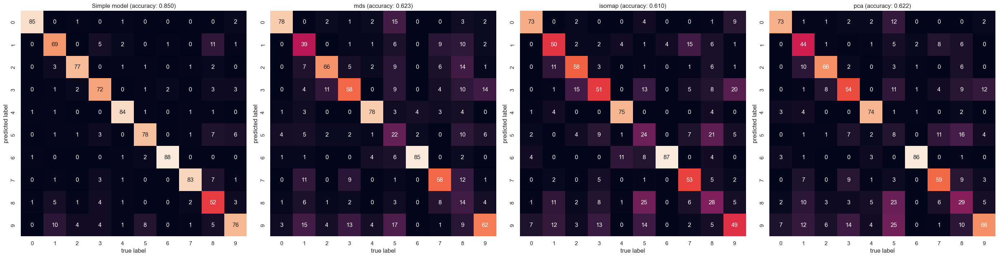

In [16]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score

trg, names, labels = get_results()
num_plots = len(names)
fig = plt.figure(figsize=(7 * num_plots, 7))

for idx in range(num_plots):
  plt.subplot(1, num_plots, 1 + idx)
  mat = confusion_matrix(trg, labels[idx])
  sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=[i for i in range(10)],
            yticklabels=[i for i in range(10)])
  plt.ylim(10.0, 0.0)
  plt.xlabel('true label')
  plt.ylabel('predicted label')

  plt.title(names[idx] + " (accuracy: " + f"{accuracy_score(trg, labels[idx]):.3f}" + ")")
plt.tight_layout()
plt.show()

### Точность в зависимости от числа компонент

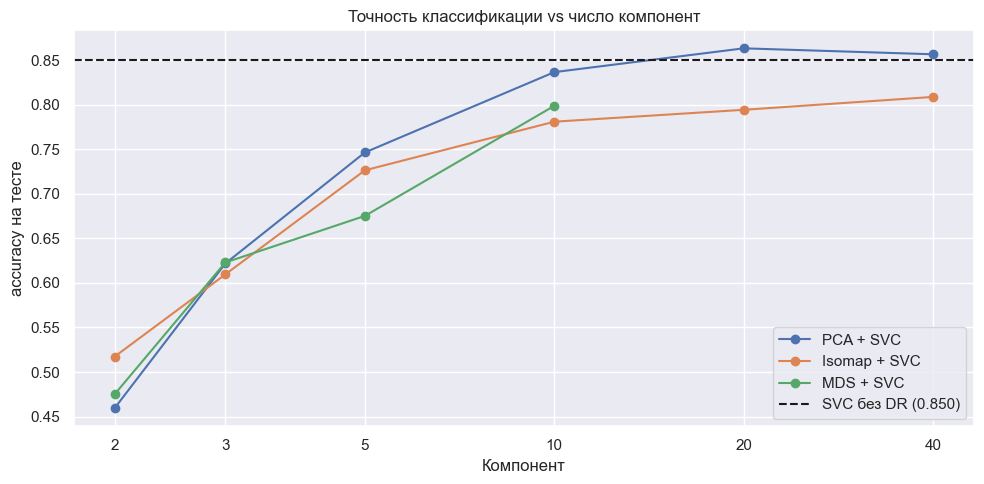

           PCA + SVC  Isomap + SVC  MDS + SVC
Компонент                                    
2              0.459         0.517      0.475
3              0.622         0.610      0.623
5              0.746         0.726      0.675
10             0.836         0.781      0.799
20             0.863         0.794        NaN
40             0.857         0.809        NaN



Isomap (10 компонент), accuracy при разных n_neighbors: {5: 0.763, 10: 0.781, 20: 0.801, 50: 0.83}


In [17]:
comps = [2, 3, 5, 10, 20, 40]
rows = []
for nc in comps:
    acc_pca = accuracy_score(y_test, Pipeline([('pca', PCA(n_components=nc, random_state=42)),
                                               ('svc', svm.SVC())]).fit(X_train, y_train).predict(X_test))
    acc_iso = accuracy_score(y_test, Pipeline([('iso', Isomap(n_components=nc, n_neighbors=10)),
                                               ('svc', svm.SVC())]).fit(X_train, y_train).predict(X_test))
    row = {'Компонент': nc, 'PCA + SVC': acc_pca, 'Isomap + SVC': acc_iso}
    if nc <= 10:
        emb = make_mds(n_components=nc, n_init=1, max_iter=300, random_state=42).fit_transform(data)
        row['MDS + SVC'] = accuracy_score(y_test, svm.SVC().fit(emb[:len(X_train)], y_train)
                                          .predict(emb[len(X_train):]))
    rows.append(row)
acc_df = pd.DataFrame(rows).set_index('Компонент')
acc_simple = accuracy_score(y_test, l_simple)

ax = acc_df.plot(marker='o', figsize=(10, 5))
ax.axhline(acc_simple, color='k', linestyle='--', label=f'SVC без DR ({acc_simple:.3f})')
ax.set_xscale('log'); ax.set_xticks(comps); ax.set_xticklabels(comps)
ax.set_ylabel('accuracy на тесте'); ax.set_title('Точность классификации vs число компонент')
ax.legend(); plt.tight_layout(); plt.show()
print(acc_df.round(3))

iso_k = {k: accuracy_score(y_test, Pipeline([('iso', Isomap(n_components=10, n_neighbors=k)),
                                             ('svc', svm.SVC())]).fit(X_train, y_train).predict(X_test))
         for k in [5, 10, 20, 50]}
print("\nIsomap (10 компонент), accuracy при разных n_neighbors:", {k: round(v, 3) for k, v in iso_k.items()})

- Без DR: 0.85. С 3 компонентами у всех ≈ 0.61–0.62. С 2 компонентами лучше Isomap (0.52 против 0.46).
- PCA с 20 компонентами (0.86) лучше модели без DR - убирает шум.
- Isomap насыщается на ≈ 0.81; на шумных данных ему лучше больше соседей (k = 50 → 0.83).
- Путаются 5 ↔ 0/8/9, 8 ↔ 5/1/2, 3 ↔ 9, 1 ↔ 7.

## Выводы
- MDS годится только для почти линейных поверхностей.
- LLE и Isomap разворачивают нелинейные, но сильно зависят от n_neighbors.
- Сферу без искажений не развернуть.
- Для классификации цифр лучше PCA с ~20 компонентами.